In [30]:
pip install pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [31]:
import pandas as pd 
df=pd.read_csv('auto_mpg (1).csv')
df

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino
...,...,...,...,...,...,...,...,...,...
393,27.0,4,140.0,86.0,2790,15.6,82,usa,ford mustang gl
394,44.0,4,97.0,52.0,2130,24.6,82,europe,vw pickup
395,32.0,4,135.0,84.0,2295,11.6,82,usa,dodge rampage
396,28.0,4,120.0,79.0,2625,18.6,82,usa,ford ranger


In [32]:
df.drop('name', axis=1, inplace=True)
print(df.columns)

Index(['mpg', 'cylinders', 'displacement', 'horsepower', 'weight',
       'acceleration', 'model_year', 'origin'],
      dtype='str')


In [33]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['origin'] = le.fit_transform(df['origin'])
print(df)
print(df['origin'].unique())

      mpg  cylinders  displacement  horsepower  weight  acceleration  \
0    18.0          8         307.0       130.0    3504          12.0   
1    15.0          8         350.0       165.0    3693          11.5   
2    18.0          8         318.0       150.0    3436          11.0   
3    16.0          8         304.0       150.0    3433          12.0   
4    17.0          8         302.0       140.0    3449          10.5   
..    ...        ...           ...         ...     ...           ...   
393  27.0          4         140.0        86.0    2790          15.6   
394  44.0          4          97.0        52.0    2130          24.6   
395  32.0          4         135.0        84.0    2295          11.6   
396  28.0          4         120.0        79.0    2625          18.6   
397  31.0          4         119.0        82.0    2720          19.4   

     model_year  origin  
0            70       2  
1            70       2  
2            70       2  
3            70       2  
4    

In [34]:
df.isnull().sum()

mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
dtype: int64

In [35]:
print(df['origin'].unique())

[2 1 0]


In [36]:
df.ffill(inplace=True)
df.isnull().sum()

mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model_year      0
origin          0
dtype: int64

In [37]:
x = df.iloc[:, 1:8]
y = df[['mpg']]

In [38]:
x

,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
0,8,307.0,130.0,3504,12.0,70,2
1,8,350.0,165.0,3693,11.5,70,2
2,8,318.0,150.0,3436,11.0,70,2
3,8,304.0,150.0,3433,12.0,70,2
4,8,302.0,140.0,3449,10.5,70,2
...,...,...,...,...,...,...,...
393,4,140.0,86.0,2790,15.6,82,2
394,4,97.0,52.0,2130,24.6,82,0
395,4,135.0,84.0,2295,11.6,82,2
396,4,120.0,79.0,2625,18.6,82,2


In [39]:
y


,mpg
0,18.0
1,15.0
2,18.0
3,16.0
4,17.0
...,...
393,27.0
394,44.0
395,32.0
396,28.0


In [40]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42)
print("Training set size:", x_train.shape[0])
print("Testing set size:", x_test.shape[0])

Training set size: 318
Testing set size: 80


In [41]:
x_train

,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
3,8,304.0,150.0,3433,12.0,70,2
18,4,97.0,88.0,2130,14.5,70,1
376,4,91.0,68.0,2025,18.2,82,1
248,4,91.0,60.0,1800,16.4,78,1
177,4,115.0,95.0,2694,15.0,75,0
...,...,...,...,...,...,...,...
71,3,70.0,97.0,2330,13.5,72,1
106,8,350.0,180.0,4499,12.5,73,2
270,4,134.0,95.0,2515,14.8,78,1
348,4,89.0,62.0,2050,17.3,81,1


In [42]:
x_test

,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
198,4,91.0,53.0,1795,17.4,76,1
396,4,120.0,79.0,2625,18.6,82,2
33,6,232.0,100.0,2634,13.0,71,2
208,8,318.0,150.0,3940,13.2,76,2
93,8,318.0,150.0,4237,14.5,73,2
...,...,...,...,...,...,...,...
249,8,260.0,110.0,3365,15.5,78,2
225,6,250.0,110.0,3520,16.4,77,2
367,4,112.0,88.0,2605,19.6,82,2
175,4,90.0,70.0,1937,14.0,75,0


In [43]:
y_test

,mpg
198,33.0
396,28.0
33,19.0
208,13.0
93,14.0
...,...
249,19.9
225,17.5
367,28.0
175,29.0


In [44]:
y_train

,mpg
3,16.0
18,27.0
376,37.0
248,36.1
177,23.0
...,...
71,19.0
106,12.0
270,21.1
348,37.7


In [45]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(x_train, y_train)
y_pred = lr.predict(x_test)
print("Predicted MPG values:")
print(y_pred)

Predicted MPG values:
[[31.74305214]
 [29.55696185]
 [21.41969209]
 [16.9134972 ]
 [12.33089273]
 [25.86099722]
 [27.87991334]
 [ 9.84060817]
 [16.69997257]
 [21.95550879]
 [13.01994293]
 [35.24484675]
 [24.92405339]
 [13.6377602 ]
 [23.73304758]
 [ 6.03446532]
 [29.57830775]
 [25.2187804 ]
 [16.63306118]
 [35.35524776]
 [24.9823826 ]
 [18.78586131]
 [29.15350667]
 [28.78060912]
 [15.00067476]
 [36.37054178]
 [26.92129808]
 [24.79641364]
 [22.0118234 ]
 [ 8.54209682]
 [28.43761726]
 [36.79296616]
 [20.76108924]
 [24.70253141]
 [33.20254899]
 [12.23820086]
 [22.98356457]
 [22.15294492]
 [12.11751621]
 [28.22602656]
 [26.504525  ]
 [28.876861  ]
 [21.33707   ]
 [ 7.05870056]
 [23.08679534]
 [34.05992581]
 [28.26094222]
 [25.65286564]
 [23.77999427]
 [29.02953071]
 [22.34272272]
 [32.61088636]
 [31.55038086]
 [10.96315002]
 [28.03332266]
 [ 9.91996806]
 [20.10629959]
 [28.66866953]
 [22.98269048]
 [20.33034415]
 [16.47537204]
 [30.91162729]
 [23.7841449 ]
 [21.55431082]
 [20.81480983]
 [2

In [46]:
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
mse=mean_squared_error(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)
print("Mean squared error:",mse)
print("Mean absoulate error:",mae)
print("R_squared score:",r2)

Mean squared error: 8.879519070008019
Mean absoulate error: 2.4317564350004197
R_squared score: 0.8348501695351942


In [47]:
import numpy as np
rmse=np.sqrt(mse)
print(rmse)

2.9798521892885925


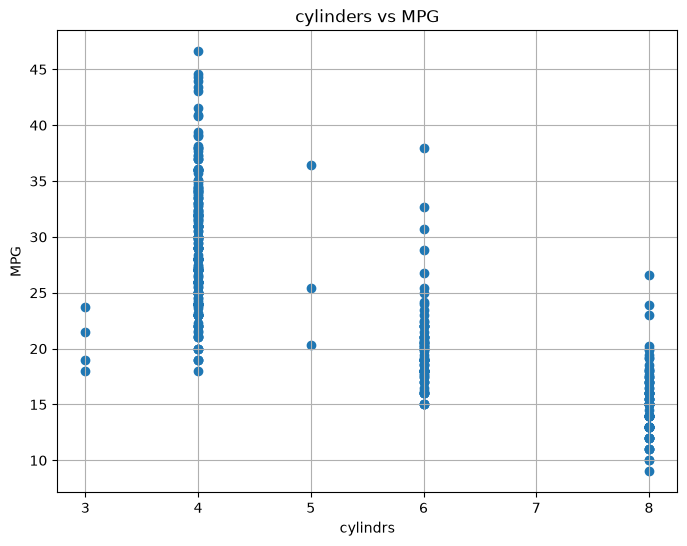

In [48]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,6))
plt.scatter(x['cylinders'],y)
plt.title("cylinders vs MPG")
plt.xlabel('cylindrs')
plt.ylabel('MPG')
plt.grid(True)
plt.show()